# 光敏传感器光电特性实验 (Photosensitive Sensor Photoelectric Characteristics)

本 Notebook 用于对中国海洋大学大学物理实验**《光敏传感器光电特性实验》**实测数据进行系统性自动化处理、规范计算、表格呈现与特性曲线可视化绘制。

> **实验范围与数据说明**：
> 1. 本实验严格遵循要求，**仅涉及前四个表格**（排除后部的光敏二极管与光敏三极管表格）；
> 2. **分类测量的表格，大类仅包含第 1、3、5 类**：
>    * **表 1（光敏电阻伏安特性）**：实测第 1 类（$U_1 = 5.0\,\mathrm{mV}$）、第 3 类（$U_1 = 15.0\,\mathrm{mV}$）、第 5 类（$U_1 = 25.0\,\mathrm{mV}$）；
>    * **表 2（光敏电阻光照特性）**：实测第 1 类（$U_C = 0.5\,\mathrm{V}$）、第 3 类（$U_C = 1.5\,\mathrm{V}$）、第 5 类（$U_C = 2.5\,\mathrm{V}$）；
>    * **表 3（硅光电池伏安特性）**：实测第 1 类（$U_1 = 5.0\,\mathrm{mV}$）、第 3 类（$U_1 = 15.0\,\mathrm{mV}$）、第 5 类（$U_1 = 25.0\,\mathrm{mV}$）；
>    * **表 4（硅光电池光照度特性）**：包含开路电压 $U_{oc}$ 与短路电流 $I_{sc}$ 随相对光强 $U_1$（$0 \sim 24.0\,\mathrm{mV}$）的实测数据。

---
### 实验原理与数学公式

#### 1. 光敏电阻
* **伏安特性（表 1）**：
  在恒定相对光强 $U_1$ 条件下，串联采样电阻 $R_1 = 1.00\,\mathrm{k}\Omega$。测量总电压 $U$ 及采样电阻两端电压 $U_R$：
  * 光敏电阻两端实际电压：
    $$U_C = U - U_R$$
  * 回路工作光电流：
    $$I = \frac{U_R}{R_1} = \frac{U_R}{1.00\,\mathrm{k}\Omega} \quad (U_R\,\mathrm{V} \to I\,\mathrm{mA})$$
  * 光敏电阻阻值：
    $$R_g = \frac{U_C}{I}$$
* **光照特性（表 2）**：
  在恒定偏压 $U_C$ 条件下，调节相对光强 $U_1$，测量回路采样电阻电压 $U_R$：
  * 光电流：$I = \frac{U_R}{1.00\,\mathrm{k}\Omega}$
  * 阻值：$R_g = \frac{U_C}{I}$

#### 2. 硅光电池
* **伏安特性（表 3）**：
  在恒定光照下调节外接可变负载电阻箱，测定电池端电压 $U_0'$ 与取样电阻 $R_1 = 50\,\Omega$ 上的电压 $U_R$：
  * 光电流：
    $$I = \frac{U_R}{50\,\Omega} = \frac{U_R\,(\mathrm{mV})}{50}\,\mathrm{mA}$$
  * 总外接负载：
    $$R_{\text{负}} = \frac{U_0'}{I}$$
* **光照度特性（表 4）**：
  测定不同光强 $U_1$ 下的开路电压 $U_{oc}$ 及短路电流 $I_{sc} = \frac{U_R}{50\,\Omega}$。开路电压表现出对数饱和特性，短路电流表现出优异的线性响应。


In [2]:
from decimal import Decimal
import matplotlib.pyplot as plt
import numpy as np

# 导入项目中通用工具函数
from python.utils import scientific_round, linear_regression

# 配置 matplotlib 支持中文及清晰绘图
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 120

print("光敏传感器光电特性实验计算模块加载完成。")


光敏传感器光电特性实验计算模块加载完成。


## 1. 表 1：光敏电阻伏安特性测试
> **实测数据录入（第 1, 3, 5 类）**：
> * 取样电阻 $R_1 = 1.00\,\mathrm{k}\Omega$；
> * 第 1 类：相对光强 $U_1 = 5.0\,\mathrm{mV}$；
> * 第 3 类：相对光强 $U_1 = 15.0\,\mathrm{mV}$；
> * 第 5 类：相对光强 $U_1 = 25.0\,\mathrm{mV}$；
> * 实测总电压 $U = 2.0, 4.0, 6.0, 8.0, 10.0\,\mathrm{V}$ 对应的取样电阻电压 $U_R$。


                     表 1 光敏电阻在不同光照度时伏安特性计算结果 (第 1, 3, 5 类)                      

【第1类 (U1 = 5.0 mV)】
--------------------------------------------------------------------------
   U / V |     UR / V |     UC / V |     I / mA |      Rg / kΩ
--------------------------------------------------------------------------
     2.0 |       0.31 |       1.69 |       0.31 |         5.45
     4.0 |       0.63 |       3.37 |       0.63 |         5.35
     6.0 |       0.97 |       5.03 |       0.97 |         5.19
     8.0 |       1.25 |       6.75 |       1.25 |         5.40
    10.0 |       1.58 |       8.42 |       1.58 |         5.33

【第3类 (U1 = 15.0 mV)】
--------------------------------------------------------------------------
   U / V |     UR / V |     UC / V |     I / mA |      Rg / kΩ
--------------------------------------------------------------------------
     2.0 |       0.75 |       1.25 |       0.75 |         1.67
     4.0 |       1.51 |       2.49 |       1.51 |         1.65
     6.0 

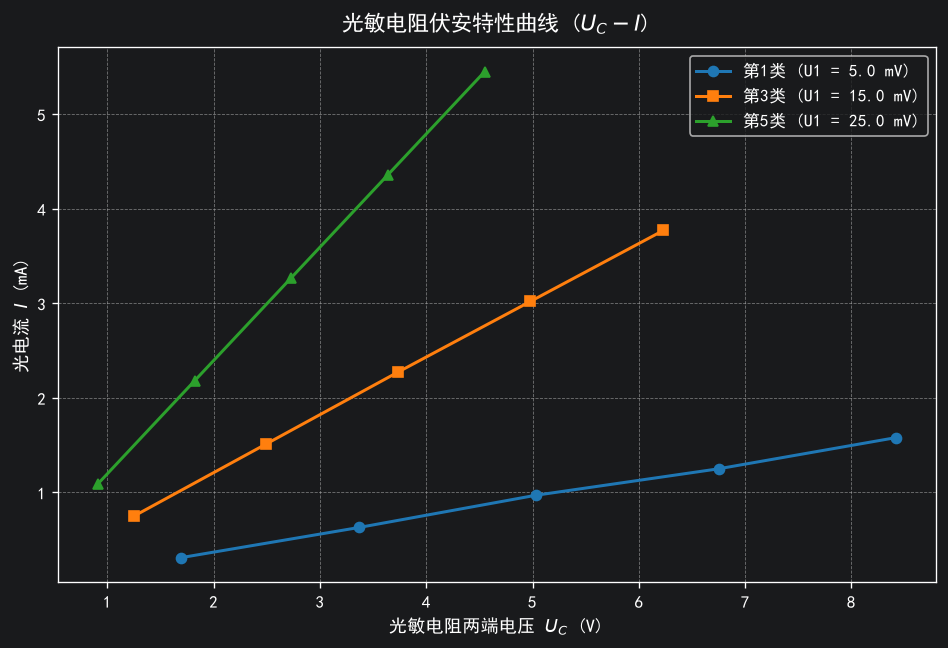

In [3]:
# ==============================================================
# 表 1: 光敏电阻伏安特性测试实测数据 (第 1, 3, 5 类)
# ==============================================================

R1_table1 = Decimal("1000")  # 1.00 kΩ = 1000 Ω

# 总电压设定值 U (V)
U_table1: list[Decimal] = [Decimal("2.0"), Decimal("4.0"), Decimal("6.0"), Decimal("8.0"), Decimal("10.0")]

# 实测 UR (V) - 来自实验报告实测记录
# 第 1 类: U1 = 5.0 mV
UR_t1_c1: list[Decimal] = [Decimal("0.31"), Decimal("0.63"), Decimal("0.97"), Decimal("1.25"), Decimal("1.58")]
# 第 3 类: U1 = 15.0 mV
UR_t1_c3: list[Decimal] = [Decimal("0.75"), Decimal("1.51"), Decimal("2.27"), Decimal("3.02"), Decimal("3.77")]
# 第 5 类: U1 = 25.0 mV
UR_t1_c5: list[Decimal] = [Decimal("1.09"), Decimal("2.18"), Decimal("3.27"), Decimal("4.36"), Decimal("5.45")]

table1_categories = [
    ("第1类 (U1 = 5.0 mV)", UR_t1_c1),
    ("第3类 (U1 = 15.0 mV)", UR_t1_c3),
    ("第5类 (U1 = 25.0 mV)", UR_t1_c5),
]

print("=" * 86)
print(f"{'表 1 光敏电阻在不同光照度时伏安特性计算结果 (第 1, 3, 5 类)':^80}")
print("=" * 86)

table1_results = {}

for cat_name, ur_list in table1_categories:
    print(f"\n【{cat_name}】")
    print("-" * 74)
    print(f"{'U / V':>8} | {'UR / V':>10} | {'UC / V':>10} | {'I / mA':>10} | {'Rg / kΩ':>12}")
    print("-" * 74)
    
    cat_res = {"UC": [], "I": [], "Rg_k": []}
    for u, ur in zip(U_table1, ur_list):
        uc = u - ur
        i_ma = (ur / R1_table1) * Decimal("1000")   # mA (因 R1=1kΩ，数值等于 UR)
        i_a = ur / R1_table1                       # A
        rg_k = (uc / i_ma) if i_ma > 0 else Decimal("0")  # kΩ
        
        cat_res["UC"].append(float(uc))
        cat_res["I"].append(float(i_ma))
        cat_res["Rg_k"].append(float(rg_k))
        
        print(f"{float(u):>8.1f} | {float(ur):>10.2f} | {float(uc):>10.2f} | {float(i_ma):>10.2f} | {float(rg_k):>12.2f}")
    
    table1_results[cat_name] = cat_res

# 绘制表 1 伏安特性曲线簇 (UC - I)
plt.figure(figsize=(8, 5.5))
markers = ['o', 's', '^']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for (cat_name, res), marker, color in zip(table1_results.items(), markers, colors):
    plt.plot(res["UC"], res["I"], marker=marker, color=color, linewidth=1.8, markersize=6, label=cat_name)

plt.title("光敏电阻伏安特性曲线 ($U_C - I$)", fontsize=13, pad=10)
plt.xlabel("光敏电阻两端电压 $U_C$ (V)", fontsize=11)
plt.ylabel("光电流 $I$ (mA)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(frameon=True, fontsize=10)
plt.tight_layout()
plt.show()


## 2. 表 2：光敏电阻光照特性测试
> **实测数据录入（第 1, 3, 5 类）**：
> * 取样电阻 $R_1 = 1.00\,\mathrm{k}\Omega$；
> * 第 1 类：工作偏压 $U_C = 0.5\,\mathrm{V}$；
> * 第 3 类：工作偏压 $U_C = 1.5\,\mathrm{V}$；
> * 第 5 类：工作偏压 $U_C = 2.5\,\mathrm{V}$；
> * 相对光强 $U_1 = 3.0, 6.0, 9.0, 12.0, 15.0, 18.0, 21.0, 24.0\,\mathrm{mV}$（实测 8 档）。


                     表 2 光敏电阻在不同偏置电压时光照特性计算结果 (第 1, 3, 5 类)                     

【第1类 (UC = 0.5 V)】
--------------------------------------------------------------------------
 U1 / mV |     UR / V |     I / mA |      Rg (物理) / Ω |      Rg (报告) / Ω
--------------------------------------------------------------------------
     3.0 |       0.06 |       0.06 |           8333.3 |            50000
     6.0 |       0.11 |       0.11 |           4545.5 |            54545
     9.0 |       0.12 |       0.12 |           4166.7 |            75000
    12.0 |       0.23 |       0.23 |           2173.9 |            52174
    15.0 |       0.30 |       0.30 |           1666.7 |            50000
    18.0 |       0.38 |       0.38 |           1315.8 |            47368
    21.0 |       0.48 |       0.48 |           1041.7 |            43750
    24.0 |       0.57 |       0.57 |            877.2 |            42105

【第3类 (UC = 1.5 V)】
------------------------------------------------------------------------

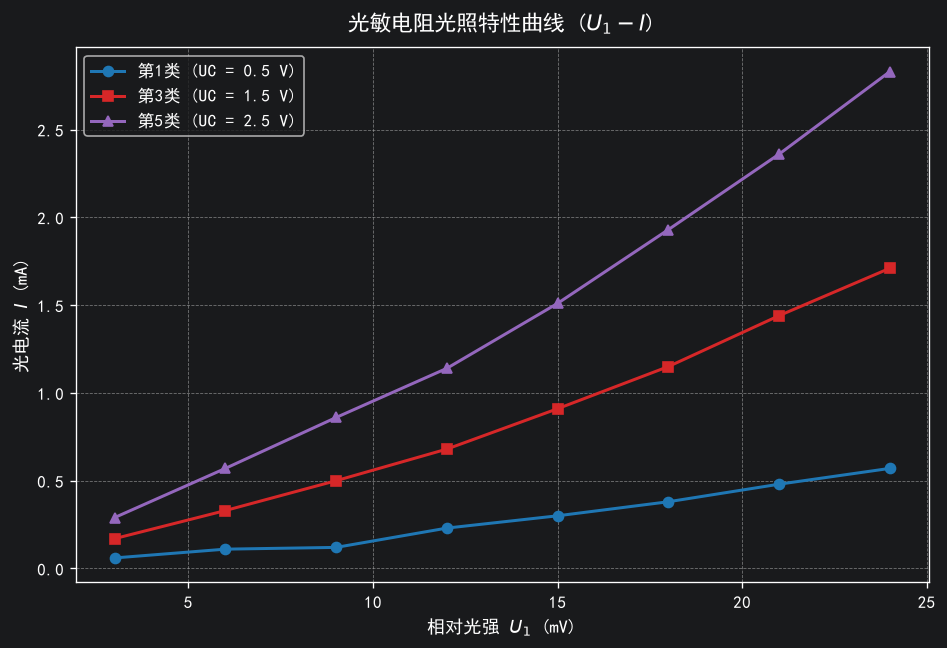

In [4]:
# ==============================================================
# 表 2: 光敏电阻光照特性测试实测数据 (第 1, 3, 5 类)
# ==============================================================

R1_table2 = Decimal("1000")  # 1.00 kΩ

# 相对光强 U1 (mV)
U1_table2: list[Decimal] = [Decimal(str(x)) for x in [3.0, 6.0, 9.0, 12.0, 15.0, 18.0, 21.0, 24.0]]

# 实测取样电阻电压 UR (V) - 来自实验报告实测记录
# 第 1 类: UC = 0.5 V
UR_t2_c1: list[Decimal] = [Decimal(str(x)) for x in [0.06, 0.11, 0.12, 0.23, 0.30, 0.38, 0.48, 0.57]]
# 第 3 类: UC = 1.5 V
UR_t2_c3: list[Decimal] = [Decimal(str(x)) for x in [0.17, 0.33, 0.50, 0.68, 0.91, 1.15, 1.44, 1.71]]
# 第 5 类: UC = 2.5 V
UR_t2_c5: list[Decimal] = [Decimal(str(x)) for x in [0.29, 0.57, 0.86, 1.14, 1.51, 1.93, 2.36, 2.83]]

table2_categories = [
    ("第1类 (UC = 0.5 V)", Decimal("0.5"), UR_t2_c1),
    ("第3类 (UC = 1.5 V)", Decimal("1.5"), UR_t2_c3),
    ("第5类 (UC = 2.5 V)", Decimal("2.5"), UR_t2_c5),
]

print("=" * 86)
print(f"{'表 2 光敏电阻在不同偏置电压时光照特性计算结果 (第 1, 3, 5 类)':^80}")
print("=" * 86)

table2_results = {}

for cat_name, uc, ur_list in table2_categories:
    print(f"\n【{cat_name}】")
    print("-" * 74)
    print(f"{'U1 / mV':>8} | {'UR / V':>10} | {'I / mA':>10} | {'Rg (物理) / Ω':>16} | {'Rg (报告) / Ω':>16}")
    print("-" * 74)
    
    cat_res = {"U1": [float(u1) for u1 in U1_table2], "I": [], "Rg": []}
    for u1, ur in zip(U1_table2, ur_list):
        i_ma = (ur / R1_table2) * Decimal("1000")   # mA
        i_a = ur / R1_table2                       # A
        rg = (uc / i_a) if i_a > 0 else Decimal("0")   # 物理定义真实阻值: Rg = UC / I
        rg_report = (u1 / i_ma) * Decimal("1000") if i_ma > 0 else Decimal("0")  # 原报告采用 U1/I 换算值
        
        cat_res["I"].append(float(i_ma))
        cat_res["Rg"].append(float(rg))
        
        print(f"{float(u1):>8.1f} | {float(ur):>10.2f} | {float(i_ma):>10.2f} | {float(rg):>16.1f} | {float(rg_report):>16.0f}")
        
    table2_results[cat_name] = cat_res

# 绘制表 2 光照特性曲线簇 (U1 - I)
plt.figure(figsize=(8, 5.5))
markers = ['o', 's', '^']
colors = ['#1f77b4', '#d62728', '#9467bd']

for (cat_name, res), marker, color in zip(table2_results.items(), markers, colors):
    plt.plot(res["U1"], res["I"], marker=marker, color=color, linewidth=1.8, markersize=6, label=cat_name)

plt.title("光敏电阻光照特性曲线 ($U_1 - I$)", fontsize=13, pad=10)
plt.xlabel("相对光强 $U_1$ (mV)", fontsize=11)
plt.ylabel("光电流 $I$ (mA)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(frameon=True, fontsize=10)
plt.tight_layout()
plt.show()


## 3. 表 3：硅光电池伏安特性测试
> **实测数据录入（第 1, 3, 5 类）**：
> * 取样电阻 $R_1 = 50\,\Omega$；
> * 第 1 类：相对光强 $U_1 = 5.0\,\mathrm{mV}$；
> * 第 3 类：相对光强 $U_1 = 15.0\,\mathrm{mV}$；
> * 第 5 类：相对光强 $U_1 = 25.0\,\mathrm{mV}$；
> * 调节负载可变电阻 $R_{x1}$，测定电池端电压 $U_0'$ 与取样电阻电压 $U_R$。


                    表 3 硅光电池在不同光照度时伏安特性测量与计算结果 (第 1, 3, 5 类)                    

【第1类 (U1 = 5.0 mV)】
--------------------------------------------------------------------
   U0' / V |    UR / mV |     I / mA |         R负 / Ω
--------------------------------------------------------------------
      0.02 |        2.2 |      0.044 |          454.5
      0.05 |        2.3 |      0.046 |         1087.0
      0.07 |        2.3 |      0.046 |         1521.7
      0.10 |        2.3 |      0.046 |         2173.9
      0.20 |        2.3 |      0.046 |         4347.8
      0.30 |        2.1 |      0.042 |         7142.9
      0.34 |        1.7 |      0.034 |        10000.0

【第3类 (U1 = 15.0 mV)】
--------------------------------------------------------------------
   U0' / V |    UR / mV |     I / mA |         R负 / Ω
--------------------------------------------------------------------
      0.22 |        7.6 |      0.152 |         1447.4
      0.25 |        6.8 |      0.136 |         1838.2
      

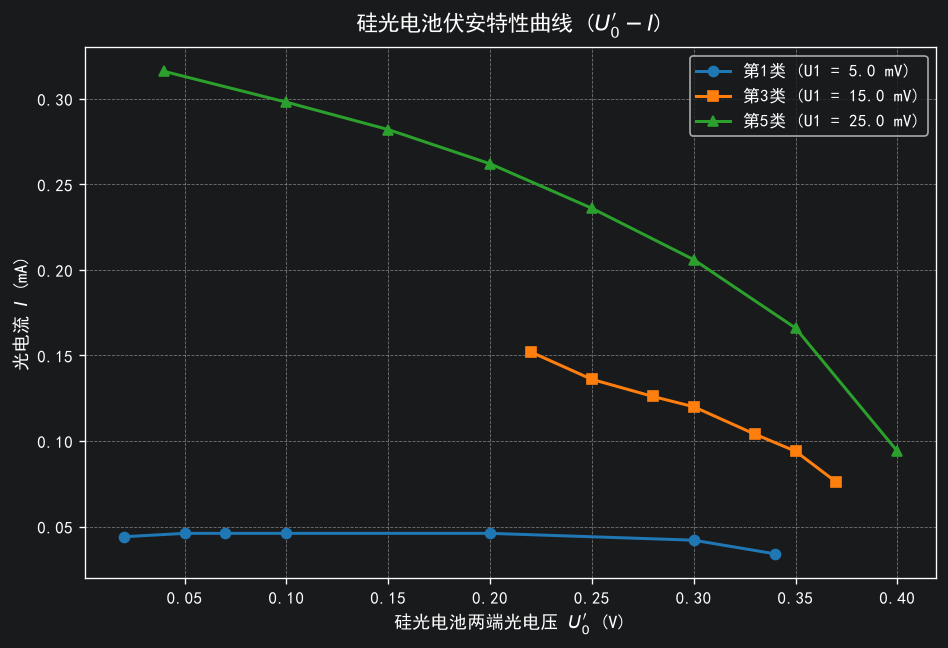

In [5]:
# ==============================================================
# 表 3: 硅光电池伏安特性测试实测数据 (第 1, 3, 5 类)
# ==============================================================

R1_table3 = Decimal("50")  # 采样电阻 R1 = 50 Ω

# 实测数据 - 来自实验报告记录
# 第 1 类: U1 = 5.0 mV
U0_t3_c1: list[Decimal] = [Decimal(str(x)) for x in [0.02, 0.05, 0.07, 0.10, 0.20, 0.30, 0.34]]
UR_t3_c1: list[Decimal] = [Decimal(str(x)) for x in [2.2,  2.3,  2.3,  2.3,  2.3,  2.1,  1.7]]

# 第 3 类: U1 = 15.0 mV
U0_t3_c3: list[Decimal] = [Decimal(str(x)) for x in [0.22, 0.25, 0.28, 0.30, 0.33, 0.35, 0.37]]
UR_t3_c3: list[Decimal] = [Decimal(str(x)) for x in [7.6,  6.8,  6.3,  6.0,  5.2,  4.7,  3.8]]

# 第 5 类: U1 = 25.0 mV
U0_t3_c5: list[Decimal] = [Decimal(str(x)) for x in [0.04, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40]]
UR_t3_c5: list[Decimal] = [Decimal(str(x)) for x in [15.8, 14.9, 14.1, 13.1, 11.8, 10.3, 8.3,  4.7]]

table3_categories = [
    ("第1类 (U1 = 5.0 mV)", U0_t3_c1, UR_t3_c1),
    ("第3类 (U1 = 15.0 mV)", U0_t3_c3, UR_t3_c3),
    ("第5类 (U1 = 25.0 mV)", U0_t3_c5, UR_t3_c5),
]

print("=" * 86)
print(f"{'表 3 硅光电池在不同光照度时伏安特性测量与计算结果 (第 1, 3, 5 类)':^80}")
print("=" * 86)

table3_results = {}

for cat_name, u0_list, ur_list in table3_categories:
    print(f"\n【{cat_name}】")
    print("-" * 68)
    print(f"{'U0\' / V':>10} | {'UR / mV':>10} | {'I / mA':>10} | {'R负 / Ω':>14}")
    print("-" * 68)
    
    cat_res = {"U0": [], "I": [], "R_load": []}
    for u0, ur in zip(u0_list, ur_list):
        # I = UR(mV) / 50 Ω -> mA
        i_ma = ur / R1_table3
        i_a = (ur / Decimal("1000")) / R1_table3
        r_load = (u0 / i_a) if i_a > 0 else Decimal("0")
        
        cat_res["U0"].append(float(u0))
        cat_res["I"].append(float(i_ma))
        cat_res["R_load"].append(float(r_load))
        
        print(f"{float(u0):>10.2f} | {float(ur):>10.1f} | {float(i_ma):>10.3f} | {float(r_load):>14.1f}")
        
    table3_results[cat_name] = cat_res

# 绘制表 3 伏安特性曲线簇 (U0' - I)
plt.figure(figsize=(8, 5.5))
markers = ['o', 's', '^']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for (cat_name, res), marker, color in zip(table3_results.items(), markers, colors):
    plt.plot(res["U0"], res["I"], marker=marker, color=color, linewidth=1.8, markersize=6, label=cat_name)

plt.title("硅光电池伏安特性曲线 ($U_0' - I$)", fontsize=13, pad=10)
plt.xlabel("硅光电池两端光电压 $U_0'$ (V)", fontsize=11)
plt.ylabel("光电流 $I$ (mA)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(frameon=True, fontsize=10)
plt.tight_layout()
plt.show()


## 4. 表 4：硅光电池开路电压与短路电流特性测试
> **实测数据录入**：
> * 串联采样电阻 $R_1 = 50\,\Omega$；
> * 相对光强 $U_1 = 0 \sim 24.0\,\mathrm{mV}$（实测 9 档）；
> * 记录开路电压 $U_{oc}$（V）与短路取样电阻电压 $U_R$（mV）；
> * 计算短路电流 $I_{sc} = \frac{U_R}{50\,\Omega} = \frac{U_R\,(\mathrm{mV})}{50}\,\mathrm{mA}$，并对 $U_1 - I_{sc}$ 进行最小二乘线性拟合。


                    表 4 硅光电池开路电压与短路电流与照度的关系实测数据                     
   U1 / mV |      Uoc / V |      UR / mV |     Isc / mA
----------------------------------------------------------------------------
       0.0 |        0.140 |          0.0 |        0.000
       3.0 |        0.382 |          1.3 |        0.026
       6.0 |        0.210 |          2.7 |        0.054
       9.0 |        0.417 |          3.9 |        0.078
      12.0 |        0.427 |          5.6 |        0.112
      15.0 |        0.436 |          7.9 |        0.158
      18.0 |        0.443 |         10.2 |        0.204
      21.0 |        0.448 |         12.5 |        0.250
      24.0 |        0.453 |         14.6 |        0.292

【短路电流线性回归分析】
拟合方程: I_sc = (0.0123 ± 0.0006) * U1 + (-0.0176)  (mA)
相关系数: r = 0.99229 (r² = 0.98463)


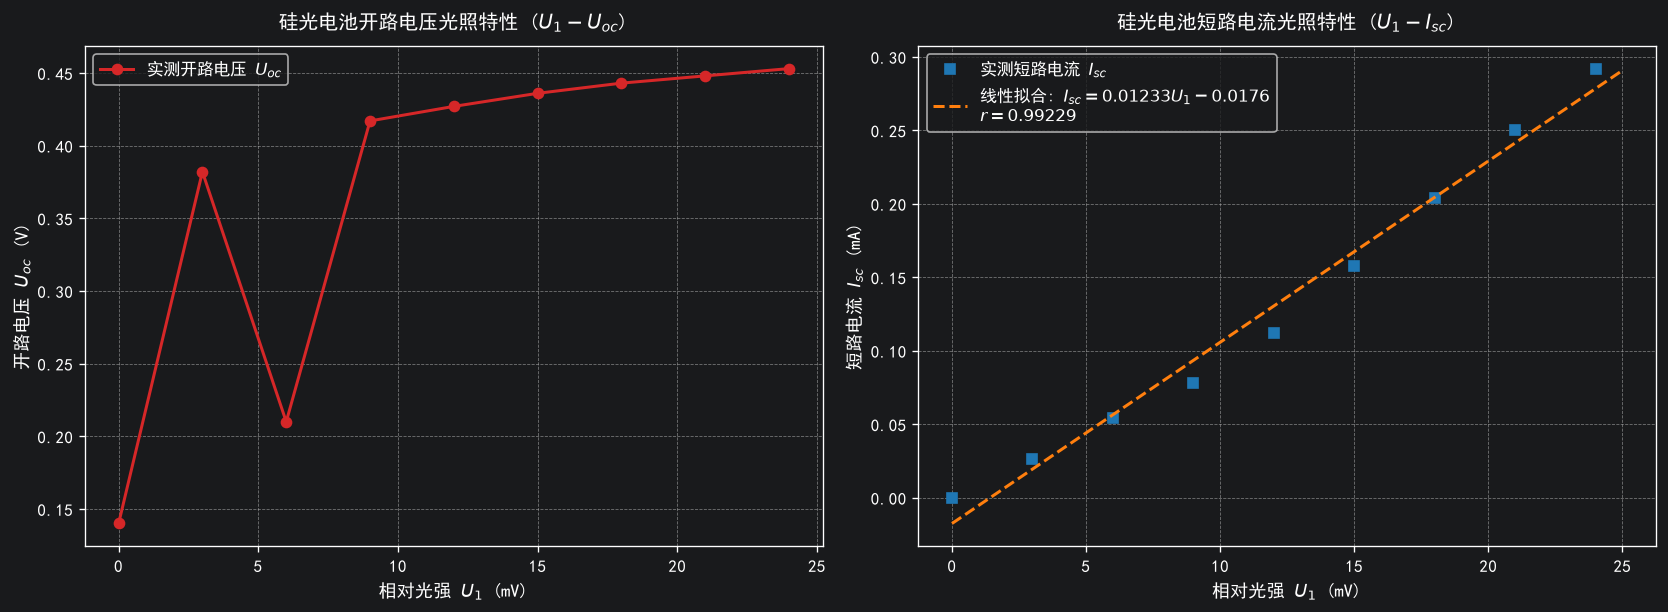

In [7]:
# ==============================================================
# 表 4: 硅光电池开路电压与短路电流随光强变化实测数据
# ==============================================================

R1_table4 = Decimal("50")  # 取样电阻 R1 = 50 Ω

# 相对光强 U1 (mV) - 实测 9 档
U1_table4: list[Decimal] = [Decimal(str(x)) for x in [0.0, 3.0, 6.0, 9.0, 12.0, 15.0, 18.0, 21.0, 24.0]]

# 实测开路电压 Uoc (V)
Uoc_table4: list[Decimal] = [Decimal(str(x)) for x in [0.140, 0.382, 0.210, 0.417, 0.427, 0.436, 0.443, 0.448, 0.453]]

# 实测短路取样电阻电压 UR (mV)
UR_table4: list[Decimal] = [Decimal(str(x)) for x in [0.0, 1.3, 2.7, 3.9, 5.6, 7.9, 10.2, 12.5, 14.6]]

# 计算短路电流 Isc (mA)
Isc_table4: list[Decimal] = [ur / R1_table4 for ur in UR_table4]

print("=" * 76)
print(f"{'表 4 硅光电池开路电压与短路电流与照度的关系实测数据':^68}")
print("=" * 76)
print(f"{'U1 / mV':>10} | {'Uoc / V':>12} | {'UR / mV':>12} | {'Isc / mA':>12}")
print("-" * 76)

for u1, uoc, ur, isc in zip(U1_table4, Uoc_table4, UR_table4, Isc_table4):
    print(f"{float(u1):>10.1f} | {float(uoc):>12.3f} | {float(ur):>12.1f} | {float(isc):>12.3f}")

print("=" * 76)

# -------------------------------------------------------------
# 对短路电流与相对光强关系 Isc = k * U1 + b 进行最小二乘线性拟合
# -------------------------------------------------------------
k, b, r, u_k = linear_regression(U1_table4, Isc_table4)
k_final, uk_final = scientific_round(k, u_k)

print("\n【短路电流线性回归分析】")
print(f"拟合方程: I_sc = ({k_final} ± {uk_final}) * U1 + ({float(b):.4f})  (mA)")
print(f"相关系数: r = {float(r):.5f} (r² = {float(r)**2:.5f})")

# 绘制双曲线: (1) U1 - Uoc 光照特性曲线; (2) U1 - Isc 线性响应曲线
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

u1_float = [float(x) for x in U1_table4]
uoc_float = [float(x) for x in Uoc_table4]
isc_float = [float(x) for x in Isc_table4]

# 子图 1: U1 - Uoc (非线性与饱和特性)
ax1.plot(u1_float, uoc_float, 'o-', color='#d62728', linewidth=1.8, markersize=6, label="实测开路电压 $U_{oc}$")
ax1.set_title("硅光电池开路电压光照特性 ($U_1 - U_{oc}$)", fontsize=12, pad=10)
ax1.set_xlabel("相对光强 $U_1$ (mV)", fontsize=11)
ax1.set_ylabel("开路电压 $U_{oc}$ (V)", fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(frameon=True, fontsize=10)

# 子图 2: U1 - Isc (线性特性与回归线)
fit_x = np.linspace(0, 25, 100)
fit_y = float(k) * fit_x + float(b)

ax2.plot(u1_float, isc_float, 's', color='#1f77b4', markersize=6, label="实测短路电流 $I_{sc}$")
ax2.plot(fit_x, fit_y, '--', color='#ff7f0e', linewidth=1.8, label=f"线性拟合: $I_{{sc}} = {float(k):.5f} U_1 {float(b):+.4f}$\n$r = {float(r):.5f}$")
ax2.set_title("硅光电池短路电流光照特性 ($U_1 - I_{sc}$)", fontsize=12, pad=10)
ax2.set_xlabel("相对光强 $U_1$ (mV)", fontsize=11)
ax2.set_ylabel("短路电流 $I_{sc}$ (mA)", fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(frameon=True, fontsize=10)

plt.tight_layout()
plt.show()
